# More PyMC

The network we have built in PyMC is quite simple, featuring only binary valued discrete random variables and conditioning on single variables. To build real-world networks we need to understand how to build more complex models.

## Networks with Multiple Parents

Consider the following Bayesian network:

$P(X,Y,Z) = P(X)P(Y)P(Z\vert X,Y)$

for binary-valued random variables $X$, $Y$, $Z$ with associated distributions

|     | $P(X)$ |
|:----|:-------|
|$X=0$| $0.2$  |
|$X=1$| $0.8$  |


|     | $P(Y)$ |
|:----|:-------|
|$Y=0$| $0.9$  |
|$Y=1$| $0.1$  |


|     | $P(Z\vert X=0, Y=0)$ | $P(Z\vert X=0, Y=1)$ | $P(Z\vert X=1, Y=0)$ | $P(Z\vert X=1, Y=1)$ |
|:----|:---------------------|:---------------------|:---------------------|:---------------------|
|$Z=0$| $0.3$                | $0.8$                | $0.9$                | $0.6$                |
|$Z=1$| $0.7$                | $0.2$                | $0.1$                | $0.4$                |



When conditioning on a single variable, we created a deterministic variable from our input distribution using the `switch` command to select the correct column from our distribution. When conditioning on multiple variables, we have to do this multiple times until we have conditioned on all the variables.

In [1]:
import numpy as np
PX = np.array([0.2,0.8])
PY = np.array([0.9,0.1])
PZ_XY = np.array([[[0.3,0.8],[0.9,0.6]],[[0.7,0.2],[0.1,0.4]]])

In [2]:
import pymc as mc
with mc.Model() as model:
    X = mc.Bernoulli('X',PX[1])
    Y = mc.Bernoulli('Y',PY[1])
    # P(Z=1 | X, Y): first select on Y, leaving a pair indexed by X, then select on X
    PZ1_X = mc.Deterministic('PZ1_X', mc.math.switch(Y,PZ_XY[1,:,1],PZ_XY[1,:,0]))
    PZ1 = mc.Deterministic('PZ1', mc.math.switch(X,PZ1_X[1],PZ1_X[0]))
    Z = mc.Bernoulli('Z', PZ1)
    step = mc.Metropolis()
    trace = mc.sample(10000, step=step, tune=5000, random_seed=123, progressbar=True)

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [X]
>Metropolis: [Y]
>Metropolis: [Z]


Output()

Sampling 4 chains for 5_000 tune and 10_000 draw iterations (20_000 + 40_000 draws total) took 3 seconds.


array([[<Axes: title={'center': 'X'}>, <Axes: title={'center': 'X'}>],
       [<Axes: title={'center': 'Y'}>, <Axes: title={'center': 'Y'}>],
       [<Axes: title={'center': 'Z'}>, <Axes: title={'center': 'Z'}>],
       [<Axes: title={'center': 'PZ1_X'}>,
        <Axes: title={'center': 'PZ1_X'}>],
       [<Axes: title={'center': 'PZ1'}>, <Axes: title={'center': 'PZ1'}>]],
      dtype=object)

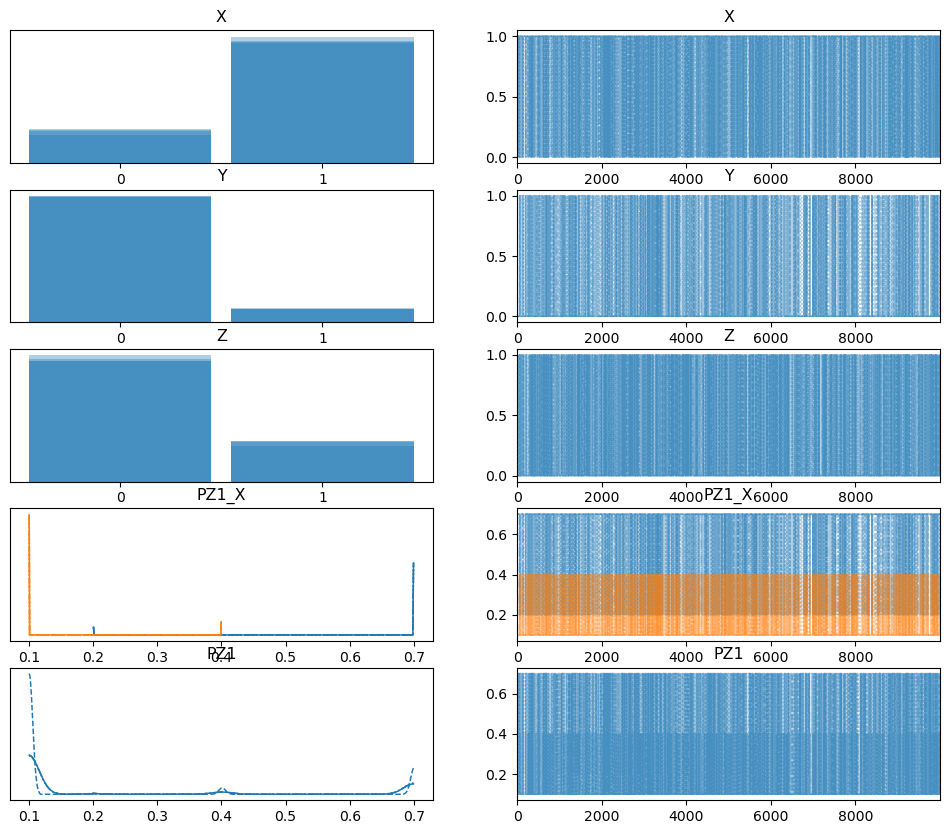

In [3]:
mc.plot_trace(trace)

Does this align with expectation? We can do the calculation analytically. In the notation of the earlier sections `PZ_XY[z][x][y]` is $P(Z=z\vert X=x,Y=y)$, so summing over $Y$ (matrix product with `PY`) gives `PZ_X`, and then summing over $X$ gives `PZ`:

In [4]:
PZ_X = PZ_XY @ PY
PZ = PZ_X @ PX
print(PZ)

[0.766 0.234]


This looks correct compared to the graph from the trace, but let's calculate from the trace as well. We just want the number of times $Z=1$ in the trace divided by the number of rows in the trace. Because successive Metropolis samples are correlated, the estimate will typically differ from the exact value in the second decimal place, and will change from run to run.

In [5]:
df = trace.to_dataframe(groups='posterior')
display(df)

,chain,draw,X,Y,Z,"(PZ1_X[0], 0)","(PZ1_X[1], 1)",PZ1
0,0,0,1,0,0,0.7,0.1,0.1
1,0,1,1,0,0,0.7,0.1,0.1
2,0,2,1,0,0,0.7,0.1,0.1
3,0,3,1,0,0,0.7,0.1,0.1
4,0,4,1,0,0,0.7,0.1,0.1
...,...,...,...,...,...,...,...,...
39995,3,9995,0,1,1,0.2,0.4,0.2
39996,3,9996,0,1,1,0.2,0.4,0.2
39997,3,9997,0,1,0,0.2,0.4,0.2
39998,3,9998,0,1,0,0.2,0.4,0.2


In [6]:
print(f"P(Z=1) from the trace = {df['Z'].mean():.4f}   (exact {PZ[1]:.4f})")

P(Z=1) from the trace = 0.2406   (exact 0.2340)


## Networks with Non-Binary variables

Let us now consider how to work with networks where the variables are discrete but non-binary valued. The analogue in PyMC of the Bernoulli distribution for non-binary discrete variables is the `Categorical` distribution. This takes a vector of probabilities, one per value. PyMC will automatically normalise this for us.

In [7]:
PX = np.array([1,2,3,4])

In [8]:
with mc.Model() as model:
    X = mc.Categorical('X', PX)
    step = mc.Metropolis()
    trace = mc.sample(100000, step=step, tune=5000, random_seed=123, progressbar=True)

/opt/anaconda3/envs/Knowledge-Engineering/lib/python3.13/site-packages/pymc/distributions/discrete.py:1142: UserWarning: `p` parameters sum to [10], instead of 1.0. They will be automatically rescaled. You can rescale them directly to get rid of this warning.
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [X]


Output()

Sampling 4 chains for 5_000 tune and 100_000 draw iterations (20_000 + 400_000 draws total) took 10 seconds.


array([[<Axes: title={'center': 'X'}>, <Axes: title={'center': 'X'}>]],
      dtype=object)

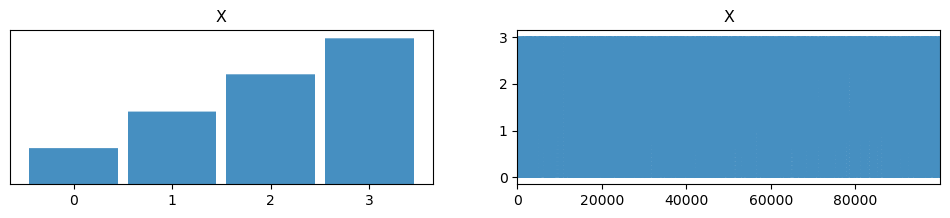

In [9]:
mc.plot_trace(trace)

In [10]:
df = trace.to_dataframe(groups='posterior')
display(df)

,chain,draw,X
0,0,0,2
1,0,1,2
2,0,2,2
3,0,3,2
4,0,4,2
...,...,...,...
399995,3,99995,3
399996,3,99996,2
399997,3,99997,1
399998,3,99998,1


In [11]:
x = 3
p = len(df[df['X']==x])/len(df)
print(f"P(X={x}) = {p} (expected {PX[x]/PX.sum()})")

P(X=3) = 0.40069 (expected 0.4)


We can use categorical variables just as we used binary variables to build networks, Consider the following (really simple) network:

$P(X,Y) = P(Y\vert X)P(X)$

where we have likelihoods

|       | $P(X)$ |
|:------|:-------|
| $X=0$ | $0.1$  |
| $X=1$ | $0.2$  |
| $X=2$ | $0.3$  |
| $X=3$ | $0.4$  |

and 

|       | $P(Y\vert X=0)$ | $P(Y\vert X=1)$ | $P(Y\vert X=2)$ | $P(Y\vert X=3)$ |
|:------|:----------------|:----------------|:----------------|:----------------|
| $Y=0$ | $0.7$           | $0.4$           | $0.2$           | $0.6$           |
| $Y=1$ | $0.2$           | $0.1$           | $0.5$           | $0.3$           |
| $Y=2$ | $0.1$           | $0.5$           | $0.3$           | $0.1$           |

In [12]:
PX = np.array([0.1,0.2,0.3,0.4])
PY_X = np.array([[0.7,0.4,0.2,0.6],[0.2,0.1,0.5,0.3],[0.1,0.5,0.3,0.1]])

PY_exact = PY_X@PX 
print(PY_exact)

[0.45 0.31 0.24]


Implementing this requires a bit more thought: The `switch` instruction only allows us to selection based on a single condition:

`switch(cond, ifCondTrue, ifCondFalse)`

This is fine for binary variables, but doesn't work for multivalued variables. One option is to nest the switches together, but this will be very painful. Another is to use the function `numpy.take` which allows us to select a slice from a matrix:

In [13]:
np.take(PY_X,3,axis=1)

array([0.6, 0.3, 0.1])

but this only works when the index is a known number, as here. Inside a model the value of $X$ is a random variable, not a number, so `numpy` cannot use it as an index at the time the line is executed.

Fortunately, the `pytensor` package has a version of `take` that is compatible with PyMC:

In [14]:
import pytensor.tensor as pt
pt.take(PY_X,3,axis=1)

Subtensor{:, i}.0

We can use this within a PyMC model in the following way:

In [15]:
with mc.Model() as model:
    X = mc.Categorical('X',PX)
    PY_given_X = pt.take(PY_X, X, axis=1)
    Y = mc.Categorical('Y', PY_given_X)
    trace = mc.sample(10000, tune=5000, random_seed=123, progressbar=True)

Multiprocess sampling (4 chains in 4 jobs)
CategoricalGibbsMetropolis: [X, Y]


Output()

Sampling 4 chains for 5_000 tune and 10_000 draw iterations (20_000 + 40_000 draws total) took 2 seconds.


We have not specified a step method, so PyMC chooses one itself: as the output shows, it uses `CategoricalGibbsMetropolis` for both variables.

Let's make sure it gives us what we expect:

array([[<Axes: title={'center': 'X'}>, <Axes: title={'center': 'X'}>],
       [<Axes: title={'center': 'Y'}>, <Axes: title={'center': 'Y'}>]],
      dtype=object)

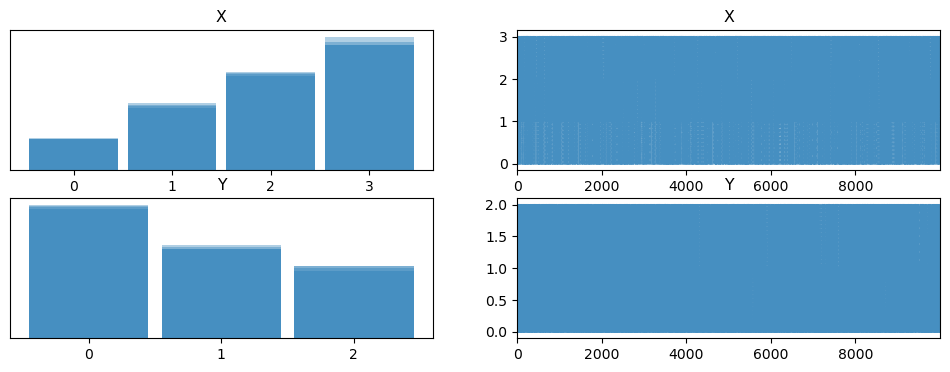

In [16]:
mc.plot_trace(trace)

In [17]:
df = trace.to_dataframe(groups='posterior')

for i in range(3):
    print(f"P(Y={i}) = {len(df[df['Y']==i])/len(df)} (exact {PY_exact[i]:.2f})")

P(Y=0) = 0.44935 (exact 0.45)
P(Y=1) = 0.31045 (exact 0.31)
P(Y=2) = 0.2402 (exact 0.24)


## Networks with Continuous Variables

Our examples of Bayesian networks have so far been limited to networks of variables that are finite-valued, or discrete. It is very common for problems of interest to contain random variables that are not discrete, but are continuous, and are thus described not by a table of probabilities but by a probability density function, or PDF.

This creates a technical issue for us: we know very well how to multiply probability tables together, although this can become a formidable exercise in combinatorics. With continuous PDFs, we do not, in general know how to do this very easily (and sometimes it is not possible at all). Approximate sampling is often the only way we have of calculating the distributions.

In continuous Bayesian networks, we want to deduce the probability distribution of some continuous random variable (or variables) that depends on some other random variables, just as we are in the discrete case. In the discrete case, we work with conditional distributions and we do the same in the continuous case. Consider the following very simple example:

* A random variable $Y$ is known to be sampled from a normal distribution the mean of which is twice some other quantity $X$ and which has standard deviation $\sigma_Y$.
* $X$ is itself a random variable and is sampled from a normal distribution with mean $\mu_X$ and standard deviation $\sigma_X$.

Using the notation $\mathcal{N}(Z\vert \mu,\sigma)$ to denote a normally distributed random variable of mean $\mu$ and variance $\sigma^2$, we can write:

* The PDF of $X$ is therefore $P(X) = \mathcal{N}(X\vert \mu_X,\sigma_X)$
* The PDF of $Y$ is conditioned on $X$ and $P(Y\vert X, \sigma_Y)=\mathcal{N}(Y\vert 2X,\sigma_Y)$

The question is, how does the distribution of $X$ affect the distribution of $Y$? We do not yet have tools to answer this. Let us explore.

PyMC supports continuous random variables. Let us build a model.


In [18]:
muX, sigX, sigY = 1.0, 0.5, 0.3
with mc.Model() as model:
    X = mc.Normal('X', mu=muX, sigma=sigX)
    Y = mc.Normal('Y', mu=2*X, sigma=sigY)
    trace = mc.sample(10000, tune=2000, random_seed=123, progressbar=True)

df = trace.to_dataframe(groups='posterior')
print(f"Mean of Y = {df['Y'].mean():.3f} (expected {2*muX})")
print(f"Std of Y = {df['Y'].std():.3f} (expected {np.sqrt(4*sigX**2+sigY**2):.3f})")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [X, Y]


Output()

Sampling 4 chains for 2_000 tune and 10_000 draw iterations (8_000 + 40_000 draws total) took 3 seconds.


Mean of Y = 2.002 (expected 2.0)
Std of Y = 1.042 (expected 1.044)


Here we chose $\mu_X=1$, $\sigma_X=0.5$ and $\sigma_Y=0.3$. For this simple linear-Gaussian network we can check the answer analytically: $Y=2X+\epsilon$ with $\epsilon\sim\mathcal{N}(0,\sigma_Y^2)$, so $Y$ is normally distributed with mean $2\mu_X$ and standard deviation $\sqrt{4\sigma_X^2+\sigma_Y^2}$.

Now consider a model in which a continuous variable has a *discrete* parent: $X$ is a binary variable and $Z$ is normally distributed with a mean that depends on $X$.

In [19]:
with mc.Model() as model:
    X = mc.Bernoulli('X',0.5)
    #Y = mc.Deterministic('Y', 5*X)
    Z = mc.Normal('Z', mu=5*X, sigma=1.0)
    trace = mc.sample(50000, tune=10000, random_seed=123, progressbar=True)

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>BinaryGibbsMetropolis: [X]
>NUTS: [Z]


Output()

Sampling 4 chains for 10_000 tune and 50_000 draw iterations (40_000 + 200_000 draws total) took 11 seconds.


array([[<Axes: title={'center': 'X'}>, <Axes: title={'center': 'X'}>],
       [<Axes: title={'center': 'Z'}>, <Axes: title={'center': 'Z'}>]],
      dtype=object)

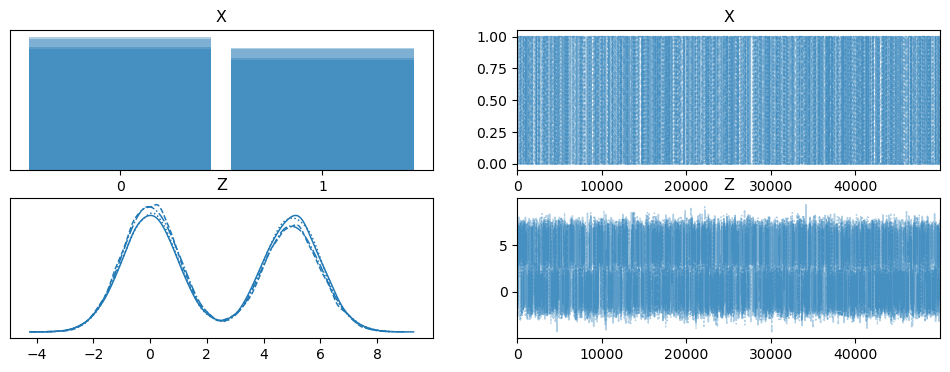

In [20]:
mc.plot_trace(trace)

What happens if you change `mu=5*X` to `mu=10*X`? The marginal distribution of $X$ is still $P(X=1)=0.5$, so a correct sampler should spend half its time in each state. Let us check, comparing the two models chain by chain.

In [21]:
for k in (5, 10):
    with mc.Model():
        X = mc.Bernoulli('X', 0.5)
        Z = mc.Normal('Z', mu=k*X, sigma=1.0)
        tr = mc.sample(5000, tune=2000, random_seed=123, progressbar=False)
    print(f"mu = {k}*X:  P(X=1) in each chain = {tr.posterior['X'].mean(dim='draw').values.round(3)}   (exact 0.5)")

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>BinaryGibbsMetropolis: [X]
>NUTS: [Z]
Sampling 4 chains for 2_000 tune and 5_000 draw iterations (8_000 + 20_000 draws total) took 1 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


mu = 5*X:  P(X=1) in each chain = [0.365 0.533 0.444 0.644]   (exact 0.5)


Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>BinaryGibbsMetropolis: [X]
>NUTS: [Z]
Sampling 4 chains for 2_000 tune and 5_000 draw iterations (8_000 + 20_000 draws total) took 1 seconds.


mu = 10*X:  P(X=1) in each chain = [1. 1. 1. 1.]   (exact 0.5)


/opt/anaconda3/envs/Knowledge-Engineering/lib/python3.13/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


With $\mu=5X$ the chains give noticeably different answers, and with $\mu=10X$ every chain is stuck. This is an artefact of the way the sampling is done: the sampler updates $X$ and $Z$ one at a time, and flipping $X$ while $Z$ is sitting in one of the modes is almost never accepted, because $Z$ would then be very unlikely under the new value of $X$ (recall that each update depends only on the Markov blanket). When there are well-separated "modes" in the distribution, many samplers can get stuck in one of the modes, as we saw with the "sticky" Markov chain earlier, and no error is reported. It is therefore important to perform some check (such as by computing the input distributions) to check that this hasn't occurred.

For a partial discussion of the issues, please see https://stats.stackexchange.com/questions/191014/gibbs-sampler-gets-stuck-in-local-mode.

## A more complicated model

You are the manager of a store that sells coats and umbrellas. Your sales data indicates that people's buying habits have a pattern:

* They buy an umbrella when the weekly rainfall exceeds 10 (arbitrary units).
* They buy a coat when the weekly rainfall exceeds 12 a.u. or the weekly temperature drops below 8 a.u.

You would like to predict the likelihood of an individual buying coats or umbrellas by season, to have better control of your stock numbers, so you decide to build a Bayesian network based on historic weather data to help you do this. The data tells you the following.

* There are four Seasons, each of equal length.
* The amount of weekly rainfall and the weekly temperature depend on the seasons.
* It is assumed that temperature and rainfall are normally distributed and that the parameters take the following values:

|     | Spring | Summer | Autumn | Winter |
|:---:|:---:|:---:|:---:|:---:|
| $\mu_R$    | 12.0 | 10.0 | 15.0 | 20.0 |
| $\sigma_R$ | 4.0 | 2.0 | 5.0 | 3.0 |
| $\mu_T$    | 15.0 | 20.0 | 10.0 | 5.0 |
| $\sigma_T$ | 3.0 | 5.0 | 5.0 | 3.0 |

The network is $P(S,R,T,U,C)=P(S)P(R\vert S)P(T\vert S)P(U\vert R)P(C\vert R,T)$: the season $S$ is a parent of rainfall $R$ and temperature $T$, which are conditionally independent given the season, and the purchases $U$ (umbrella) and $C$ (coat) are *deterministic* functions of their parents. The parameters depend on the season, so we select them with nested `switch` commands (here wrapped in a small helper function; `pt.take` on a one-dimensional array of parameters is an alternative, but it did not work in every version of PyTensor that we tried). We also write each normal variable as a standardised one scaled by $\sigma$ and shifted by $\mu$ (so $R=\mu_R+\sigma_R\,\mathrm{Rainbase}$), which is equivalent to `Normal(mu, sigma)` but lets the sampler work with variables that all have the same scale. Strictly the normal distribution allows negative rainfall, which we ignore here.

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [Season]
>Metropolis: [Rainbase]
>Metropolis: [Tempbase]


Output()

Sampling 4 chains for 10_000 tune and 100_000 draw iterations (40_000 + 400_000 draws total) took 20 seconds.


array([[<Axes: title={'center': 'Season'}>,
        <Axes: title={'center': 'Season'}>],
       [<Axes: title={'center': 'Rainbase'}>,
        <Axes: title={'center': 'Rainbase'}>],
       [<Axes: title={'center': 'Tempbase'}>,
        <Axes: title={'center': 'Tempbase'}>],
       [<Axes: title={'center': 'Rain'}>,
        <Axes: title={'center': 'Rain'}>],
       [<Axes: title={'center': 'Temperature'}>,
        <Axes: title={'center': 'Temperature'}>],
       [<Axes: title={'center': 'Umbrella'}>,
        <Axes: title={'center': 'Umbrella'}>],
       [<Axes: title={'center': 'Coat'}>,
        <Axes: title={'center': 'Coat'}>]], dtype=object)

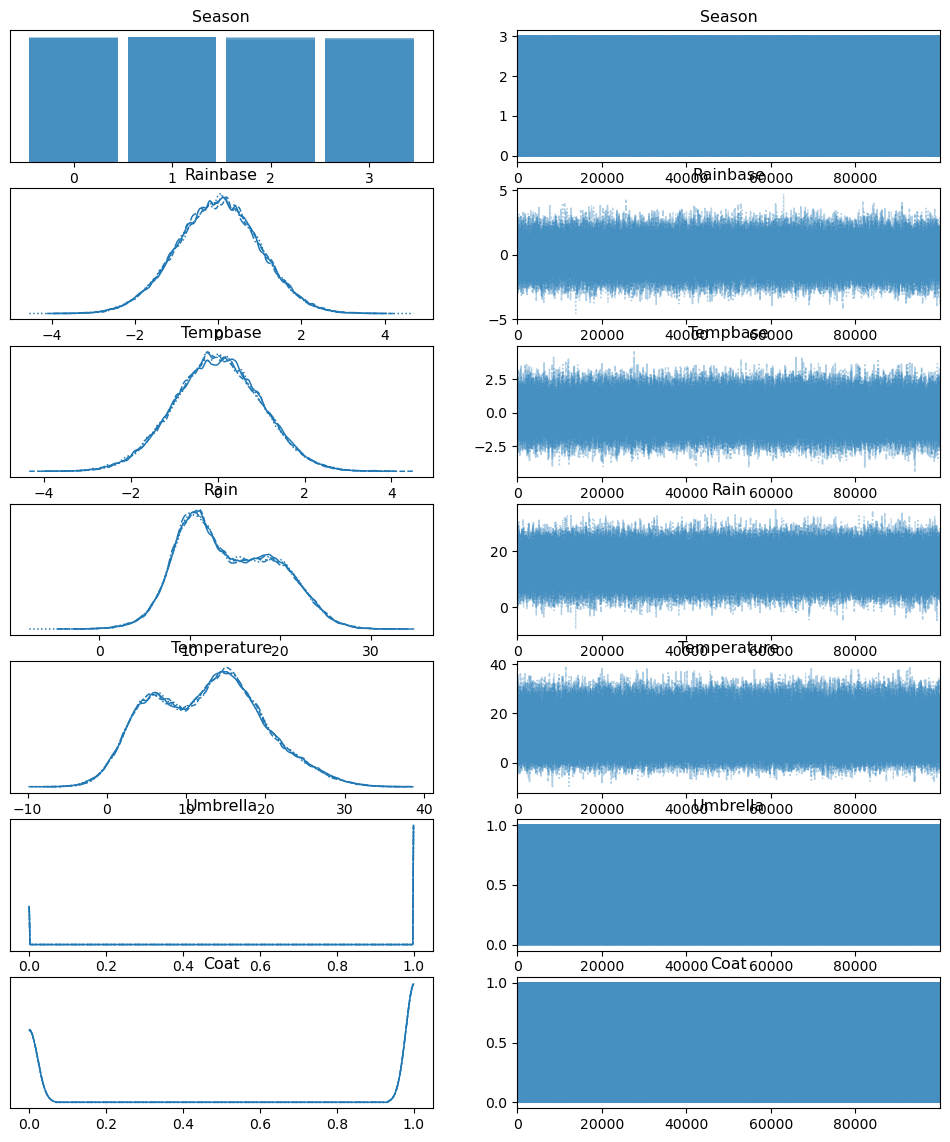

In [22]:
muR = np.array([12.0, 10.0, 15.0, 20.0]); sigR = np.array([4.0, 2.0, 5.0, 3.0])    # Spring, Summer, Autumn, Winter
muT = np.array([15.0, 20.0, 10.0, 5.0]);  sigT = np.array([3.0, 5.0, 5.0, 3.0])

with mc.Model() as model:
    S = mc.Categorical('Season', np.array([0.25, 0.25, 0.25, 0.25]))
    Rbase = mc.Normal('Rainbase', mu=0.0, sigma=1.0)
    Tbase = mc.Normal('Tempbase', mu=0.0, sigma=1.0)

    def by_season(values):
        """Select the entry of `values` (one per season) that matches the current value of S, using nested switches."""
        return mc.math.switch(mc.math.eq(S, 0), values[0],
                 mc.math.switch(mc.math.eq(S, 1), values[1],
                   mc.math.switch(mc.math.eq(S, 2), values[2], values[3])))

    R = mc.Deterministic('Rain', Rbase*by_season(sigR) + by_season(muR))
    T = mc.Deterministic('Temperature', Tbase*by_season(sigT) + by_season(muT))

    U = mc.Deterministic('Umbrella', mc.math.switch(mc.math.ge(R, 10.0), 1.0, 0.0))
    C = mc.Deterministic('Coat', mc.math.switch(mc.math.ge(R, 12.0), 1.0,
                                                mc.math.switch(mc.math.lt(T, 8.0), 1.0, 0.0)))

    step = mc.Metropolis()
    trace = mc.sample(100000, step=step, tune=10000, random_seed=123, progressbar=True)

mc.plot_trace(trace)

In [23]:
df=trace.to_dataframe(groups='posterior')

In [24]:
from scipy.stats import norm

Seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
for i, s in enumerate(Seasons):
    in_season = df[df['Season'] == i]
    P_Umbrella = in_season['Umbrella'].mean()
    P_Coat = in_season['Coat'].mean()
    # Exact: P(R >= 10 | s) and, since R and T are independent given the season, P(C | s) = 1 - P(R < 12 | s) P(T >= 8 | s)
    exact_U = 1 - norm.cdf(10, muR[i], sigR[i])
    exact_C = 1 - norm.cdf(12, muR[i], sigR[i]) * (1 - norm.cdf(8, muT[i], sigT[i]))
    print(f"{s:7s} P(Umbrella|s) = {P_Umbrella:.3f} (exact {exact_U:.3f})    P(Coat|s) = {P_Coat:.3f} (exact {exact_C:.3f})")

Spring  P(Umbrella|s) = 0.693 (exact 0.691)    P(Coat|s) = 0.510 (exact 0.505)
Summer  P(Umbrella|s) = 0.501 (exact 0.500)    P(Coat|s) = 0.164 (exact 0.166)
Autumn  P(Umbrella|s) = 0.842 (exact 0.841)    P(Coat|s) = 0.820 (exact 0.820)
Winter  P(Umbrella|s) = 1.000 (exact 1.000)    P(Coat|s) = 0.999 (exact 0.999)


### A stress test

The final example is a stress test rather than a useful model. It is a two-node network in which $C$ has 30,000 possible values and its child $P$ has 14,000, so that the conditional probability table $P(P\vert C)$ is a $14000\times 30000$ array of random numbers (about 3 GB of memory). On the machine used, drawing the $4\times10^6$ samples took around 16 minutes. It shows how the cost of sampling and the memory required grow with the number of states of each variable, even for a tiny network. You should skip this cell unless you have plenty of memory and time.

In [25]:
PC = np.random.rand(30000)
PC = PC/PC.sum()
PP_C = np.random.rand(14000,30000)
PP_C = PP_C/PP_C.sum(axis=0)

with mc.Model() as model:
    C = mc.Categorical('C',PC)
    PP = pt.take(PP_C, C, axis=1)
    P = mc.Categorical('P', PP)
    trace = mc.sample(1000000, tune=5000, random_seed=123, progressbar=True)

Multiprocess sampling (4 chains in 4 jobs)
CategoricalGibbsMetropolis: [C, P]


Output()

Sampling 4 chains for 5_000 tune and 1_000_000 draw iterations (20_000 + 4_000_000 draws total) took 1052 seconds.


array([[<Axes: title={'center': 'C'}>, <Axes: title={'center': 'C'}>],
       [<Axes: title={'center': 'P'}>, <Axes: title={'center': 'P'}>]],
      dtype=object)

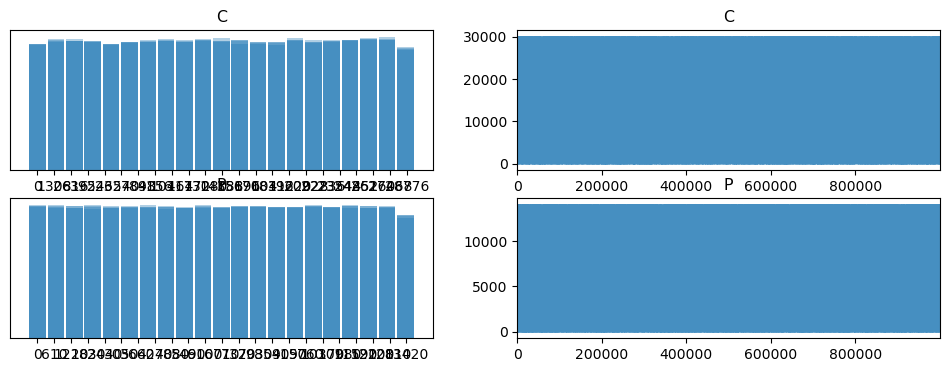

In [26]:
mc.plot_trace(trace)